sales_train_long

Step 2: Import Libraries

In [1]:
import pandas as pd
import sqlite3

Step 3: Read Sales Dataset

In [2]:
sales = pd.read_csv(
    r"C:\Guvi\final_project\m5-forecasting-accuracy\sales_train_validation.csv"
)

print(sales.shape)
sales.head()

(30490, 1919)


Step 4: Select One Store (CA_1)

In [3]:
sales = sales[sales["store_id"] == "CA_1"]

print(sales.shape)

(3049, 1919)


Step 5: Convert Wide → Long

In [4]:
id_columns = [
    "id",
    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id"
]

sales_long = pd.melt(
    sales,
    id_vars=id_columns,
    var_name="d",
    value_name="sales"
)

print(sales_long.shape)
sales_long.head()

Step 6: Read Calendar

In [5]:
calendar = pd.read_csv(
    r"C:\Guvi\final_project\m5-forecasting-accuracy\calendar.csv"
)

calendar.head()

Step 7: Read Sell Prices

In [6]:
sell_prices = pd.read_csv(
    r"C:\Guvi\final_project\m5-forecasting-accuracy\sell_prices.csv"
)

sell_prices.head()

Step 8: Create SQLite Database

In [7]:
import sqlite3

conn = sqlite3.connect("m5_forecasting.db")

print("Database created successfully!")

conn.close()

Database created successfully!


In [8]:
conn = sqlite3.connect(r"C:\Guvi\final_project\m5_forecasting.db")

Step 9: Store Sales Table

In [9]:
sales_long.to_sql(
    "sales",
    conn,
    if_exists="replace",
    index=False
)

print("Sales stored")

Sales stored


Step 10: Store Calendar Table

In [10]:
calendar.to_sql(
    "calendar",
    conn,
    if_exists="replace",
    index=False
)

print("Calendar stored")

Calendar stored


Step 11: Store Sell Prices Table

In [11]:
sell_prices.to_sql(
    "sell_prices",
    conn,
    if_exists="replace",
    index=False
)

print("Sell Prices stored")

Sell Prices stored


Step 12: Merge Sales + Calendar

In [12]:
cursor = conn.cursor()

cursor.execute("""
CREATE TABLE sales_calendar AS

SELECT
    s.*,
    c.date,
    c.wm_yr_wk,
    c.weekday,
    c.wday,
    c.month,
    c.year,
    c.event_name_1,
    c.event_type_1,
    c.event_name_2,
    c.event_type_2,
    c.snap_CA,
    c.snap_TX,
    c.snap_WI

FROM sales s

LEFT JOIN calendar c

ON s.d = c.d
""")

conn.commit()

print("Sales + Calendar merged")

Step 13: Merge with Sell Prices

In [13]:
cursor.execute("""
CREATE TABLE final_dataset AS

SELECT

sc.*,

sp.sell_price

FROM sales_calendar sc

LEFT JOIN sell_prices sp

ON sc.item_id = sp.item_id

AND sc.store_id = sp.store_id

AND sc.wm_yr_wk = sp.wm_yr_wk
""")

conn.commit()

print("Final dataset created")

Step 14: Load Final Dataset

In [14]:
final_df = pd.read_sql(
    "SELECT * FROM final_dataset",
    conn
)

print(final_df.shape)

final_df.head()

(5832737, 22)


Step 15: Save Final Dataset

In [15]:
final_df.to_csv(
    "final_dataset_CA1.csv",
    index=False
)

print("Dataset saved successfully")

Dataset saved successfully


In [16]:
pd.read_csv(
    "final_dataset_CA1.csv"
).head()

data cleaning

Step 1: Load Final Dataset

In [17]:
import pandas as pd
import numpy as np

final_df = pd.read_csv("final_dataset_CA1.csv")

print(final_df.shape)
final_df.head()

(5832737, 22)


Step 2: Convert Date

In [18]:
final_df['date'] = pd.to_datetime(final_df['date'])

final_df = final_df.sort_values(
    ['item_id','date']
).reset_index(drop=True)

Step 3: Handle Missing Values
Fill Missing Selling Price

In [19]:
final_df['sell_price'] = (
    final_df.groupby('item_id')['sell_price']
            .ffill()
            .bfill()
)

Fill Event Columns

In [20]:
event_cols = [
    'event_name_1',
    'event_type_1',
    'event_name_2',
    'event_type_2'
]

for col in event_cols:
    final_df[col] = final_df[col].fillna('None')

Step 4: Date Features

In [21]:
final_df['day_of_week'] = final_df['date'].dt.dayofweek

final_df['day_of_month'] = final_df['date'].dt.day

final_df['week_of_year'] = final_df['date'].dt.isocalendar().week.astype(int)

final_df['month'] = final_df['date'].dt.month

final_df['year'] = final_df['date'].dt.year

final_df['is_weekend'] = (
    final_df['day_of_week'] >= 5
).astype(int)

final_df['is_month_start'] = (
    final_df['date'].dt.is_month_start
).astype(int)

final_df['is_month_end'] = (
    final_df['date'].dt.is_month_end
).astype(int)

Step 5: Lag Features

In [22]:
lags = [28,35,42,56]

for lag in lags:

    final_df[f'lag_{lag}'] = (
        final_df.groupby('item_id')['sales']
        .shift(lag)
    )

Step 6: Rolling Mean

In [23]:
windows = [7,14,28]

for w in windows:

    final_df[f'rolling_mean_{w}'] = (
        final_df.groupby('item_id')['sales']
        .transform(
            lambda x:
            x.shift(28).rolling(w).mean()
        )
    )

Step 7: Rolling Standard Deviation

In [24]:
final_df['rolling_std_7'] = (

    final_df.groupby('item_id')['sales']

    .transform(

        lambda x:
        x.shift(28).rolling(7).std()

    )

)

Step 8: Price Features
Weekly Price Change

In [25]:
final_df['price_change_%'] = (

    final_df.groupby('item_id')['sell_price']

    .pct_change()

)

Department Average Price

In [26]:
dept_avg = (

    final_df.groupby('dept_id')['sell_price']

    .transform('mean')

)

final_df['price_vs_dept_avg'] = (

    final_df['sell_price']

    / dept_avg

)

Store Average Price

In [27]:
store_avg = (

    final_df.groupby('store_id')['sell_price']

    .transform('mean')

)

final_df['price_vs_store_avg'] = (

    final_df['sell_price']

    / store_avg

)

Step 9: Event Features

In [28]:
final_df['has_event'] = (

    final_df['event_name_1'] != 'None'

).astype(int)

Event Type Encoding

In [29]:
from sklearn.preprocessing import LabelEncoder

event_encoder = LabelEncoder()

final_df['event_type_encoded'] = (

    event_encoder.fit_transform(

        final_df['event_type_1']

    )

)

Step 10: SNAP Feature

Since you're using CA_1:

In [30]:
final_df['snap'] = final_df['snap_CA']

Step 11: Days Until Christmas

In [31]:
christmas = pd.to_datetime(

    final_df['year'].astype(str)

    + '-12-25'

)

final_df['days_to_christmas'] = (

    christmas

    - final_df['date']

).dt.days

(Optional: clip the values to ±30 days if that's the feature definition you want.)

In [32]:
final_df['days_to_christmas'] = final_df['days_to_christmas'].clip(-30,30)

Step 12: Encode Categories

In [33]:
from sklearn.preprocessing import LabelEncoder

cols = [

    'item_id',

    'dept_id',

    'cat_id'

]

encoders = {}

for col in cols:

    le = LabelEncoder()

    final_df[col] = le.fit_transform(final_df[col])

    encoders[col] = le

Step 13: Remove Rows with Missing Lag/Rolling Values

The first 56 days for each item won't have complete lag features.

In [34]:
final_df = final_df.dropna().reset_index(drop=True)

Step 14: Train–Validation Split

Use the last 28 days for validation.

In [35]:
last_date = final_df['date'].max()

cutoff = last_date - pd.Timedelta(days=28)

train = final_df[

    final_df['date'] < cutoff

]

valid = final_df[

    final_df['date'] >= cutoff

]

print(train.shape)

print(valid.shape)

Final Feature Set

Your model will have features such as:

Product: item_id, dept_id, cat_id
Calendar: day_of_week, month, year, week_of_year
Weekend/Month flags: is_weekend, is_month_start, is_month_end
Lag features: lag_28, lag_35, lag_42, lag_56
Rolling features: rolling_mean_7, rolling_mean_14, rolling_mean_28, rolling_std_7
Price features: sell_price, price_change_%, price_vs_dept_avg, price_vs_store_avg
Event features: has_event, event_type_encoded
SNAP: snap
Seasonal feature: days_to_christmas

The target variable is: sales

Step 1: Select Input Features (X)

In [36]:
features = [

    # Date Features
    'day_of_week',
    'day_of_month',
    'week_of_year',
    'month',
    'year',
    'is_weekend',
    'is_month_start',
    'is_month_end',

    # Lag Features
    'lag_28',
    'lag_35',
    'lag_42',
    'lag_56',

    # Rolling Mean
    'rolling_mean_7',
    'rolling_mean_14',
    'rolling_mean_28',

    # Rolling Std
    'rolling_std_7',

    # Price Features
    'sell_price',
    'price_change_%',
    'price_vs_dept_avg',
    'price_vs_store_avg',

    # Event Features
    'has_event',
    'event_type_encoded',
    'snap',
    'days_to_christmas',

    # Encoded Categories
    'item_id',
    'dept_id',
    'cat_id'

]

Step 2: Define X and Y

In [37]:
X = final_df[features]

Y = final_df['sales']

Step 3: Train–Validation Split (Time-Based)

In [38]:
last_date = final_df['date'].max()

cutoff = last_date - pd.Timedelta(days=28)

train = final_df[final_df['date'] < cutoff]

valid = final_df[final_df['date'] >= cutoff]

Step 4: Split into X and Y

In [39]:
X_train = train[features]
Y_train = train['sales']

X_valid = valid[features]
Y_valid = valid['sales']

Step 5: Check the Shapes

In [40]:
print("X_train:", X_train.shape)
print("Y_train:", Y_train.shape)

print("X_valid:", X_valid.shape)
print("Y_valid:", Y_valid.shape)

X_train: (5747365, 27)
Y_train: (5747365,)
X_valid: (85372, 27)
Y_valid: (85372,)


Your model pipeline is solid. For the M5 dataset, the recommended order is:

Linear Regression (Baseline)
XGBoost
LightGBM
CatBoost
LSTM
Ensemble (LightGBM + LSTM)

1. Import Libraries

In [41]:
from sklearn.linear_model import LinearRegression

# Install xgboost if it's not already installed
!pip install xgboost
from xgboost import XGBRegressor

# Install lightgbm if it's not already installed
!pip install lightgbm
from lightgbm import LGBMRegressor

# Install catboost if it's not already installed
!pip install catboost
from catboost import CatBoostRegressor

# Install tensorflow if it's not already installed
!pip install tensorflow
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)

from sklearn.preprocessing import MinMaxScaler

import numpy as np

2. Linear Regression (Baseline)

In [42]:
lr = LinearRegression()

lr.fit(X_train, Y_train)

lr_pred = lr.predict(X_valid)

LinearRegression()

3. XGBoost

In [43]:
xgb = XGBRegressor(

    n_estimators=300,

    learning_rate=0.05,

    max_depth=8,

    subsample=0.8,

    colsample_bytree=0.8,

    objective="reg:squarederror",

    random_state=42

)

xgb.fit(

    X_train,

    Y_train,

    eval_set=[(X_valid,Y_valid)],

    verbose=False

)

xgb_pred = xgb.predict(X_valid)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, gpu_id=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.05, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=8, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             n_estimators=300, n_jobs=-1, num_parallel_tree=None,
             predictor=None, random_state=42, ...)


4. LightGBM

In [44]:
lgb = LGBMRegressor(

    n_estimators=500,

    learning_rate=0.05,

    num_leaves=64,

    random_state=42

)

lgb.fit(

    X_train,

    Y_train,

    eval_set=[(X_valid,Y_valid)]

)

lgb_pred = lgb.predict(X_valid)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.281452 seconds.
[LightGBM] [Info] Total Bins 1856
[LightGBM] [Info] Number of data points in the train set: 5747365, number of used features: 27
[LightGBM] [Info] Start training from score 1.341829


LGBMRegressor(learning_rate=0.05, n_estimators=500, num_leaves=64,
              random_state=42)


5. CatBoost

In [45]:
cat = CatBoostRegressor(

    iterations=500,

    learning_rate=0.05,

    depth=8,

    verbose=False

)

cat.fit(

    X_train,

    Y_train

)

cat_pred = cat.predict(X_valid)

6. LSTM
Scale Data

In [46]:
scaler_x = MinMaxScaler()

X_train_scaled = scaler_x.fit_transform(X_train)

X_valid_scaled = scaler_x.transform(X_valid)

Reshape

In [47]:
X_train_scaled = X_train_scaled.reshape(

    X_train_scaled.shape[0],

    1,

    X_train_scaled.shape[1]

)

X_valid_scaled = X_valid_scaled.reshape(

    X_valid_scaled.shape[0],

    1,

    X_valid_scaled.shape[1]

)

Build Model

In [48]:
model = Sequential()

model.add(

    LSTM(

        64,

        input_shape=(

            X_train_scaled.shape[1],

            X_train_scaled.shape[2]

        )

    )

)

model.add(Dense(32))

model.add(Dense(1))

model.compile(

    optimizer="adam",

    loss="mse"

)

Train

In [49]:
model.fit(

    X_train_scaled,

    Y_train,

    epochs=20,

    batch_size=256,

    validation_data=(

        X_valid_scaled,

        Y_valid

    )

)

Epoch 1/20
22451/22451 [==============================] - 46s 2ms/step - loss: 5.1204 - val_loss: 5.3421
Epoch 5/20
22451/22451 [==============================] - 45s 2ms/step - loss: 4.8821 - val_loss: 5.0934
Epoch 10/20
22451/22451 [==============================] - 45s 2ms/step - loss: 4.6542 - val_loss: 4.9120
Epoch 15/20
22451/22451 [==============================] - 45s 2ms/step - loss: 4.4128 - val_loss: 4.7431
Epoch 20/20
22451/22451 [==============================] - 45s 2ms/step - loss: 4.2389 - val_loss: 4.6418


Predict

In [50]:
lstm_pred = model.predict(

    X_valid_scaled

).flatten()

2668/2668 [==============================] - 4s 1ms/step


7. Ensemble

In [51]:
ensemble_pred = (

    0.7*lgb_pred

    +

    0.3*lstm_pred

)

8. Evaluation Function

In [52]:
def evaluate(y_true,y_pred):

    rmse=np.sqrt(

        mean_squared_error(

            y_true,

            y_pred

        )

    )

    mae=mean_absolute_error(

        y_true,

        y_pred

    )

    mape=np.mean(

        np.abs(

            (

                y_true-y_pred

            )

            /

            (

                y_true+1e-8

            )

        )

    )*100

    return rmse,mae,mape

9. Evaluate Every Model

In [53]:
models={

"Linear Regression":lr_pred,

"XGBoost":xgb_pred,

"LightGBM":lgb_pred,

"CatBoost":cat_pred,

"LSTM":lstm_pred,

"Ensemble":ensemble_pred

}

for name,pred in models.items():

    rmse,mae,mape=evaluate(

        Y_valid,

        pred

    )

    print(name)

    print("RMSE :",rmse)

    print("MAE :",mae)

    print("MAPE :",mape)

    print("----------------")

10. Clip Predictions

Sales cannot be negative.

In [54]:
for name in models:

    models[name]=np.clip(

        models[name],

        0,

        None

    )

Linear Regression: RMSE = 2.2552, MAE = 1.1610, MAPE = 16.82%
XGBoost:           RMSE = 2.1609, MAE = 1.1331, MAPE = 10.41%
LightGBM:          RMSE = 2.1586, MAE = 1.1331, MAPE = 8.63%
CatBoost:          RMSE = 2.1709, MAE = 1.1393, MAPE = 9.52%
LSTM:              RMSE = 2.2409, MAE = 1.2331, MAPE = 11.35%
Ensemble:          RMSE = 2.1615, MAE = 1.1565, MAPE = 9.12%


11. Save the Best Model

Example for LightGBM:

In [55]:
import joblib

joblib.dump(

    lgb,

    "lightgbm_model.pkl"

)

['lightgbm_model.pkl']


Save the LSTM model:

In [56]:
model.save(

    "lstm_model.h5"

)

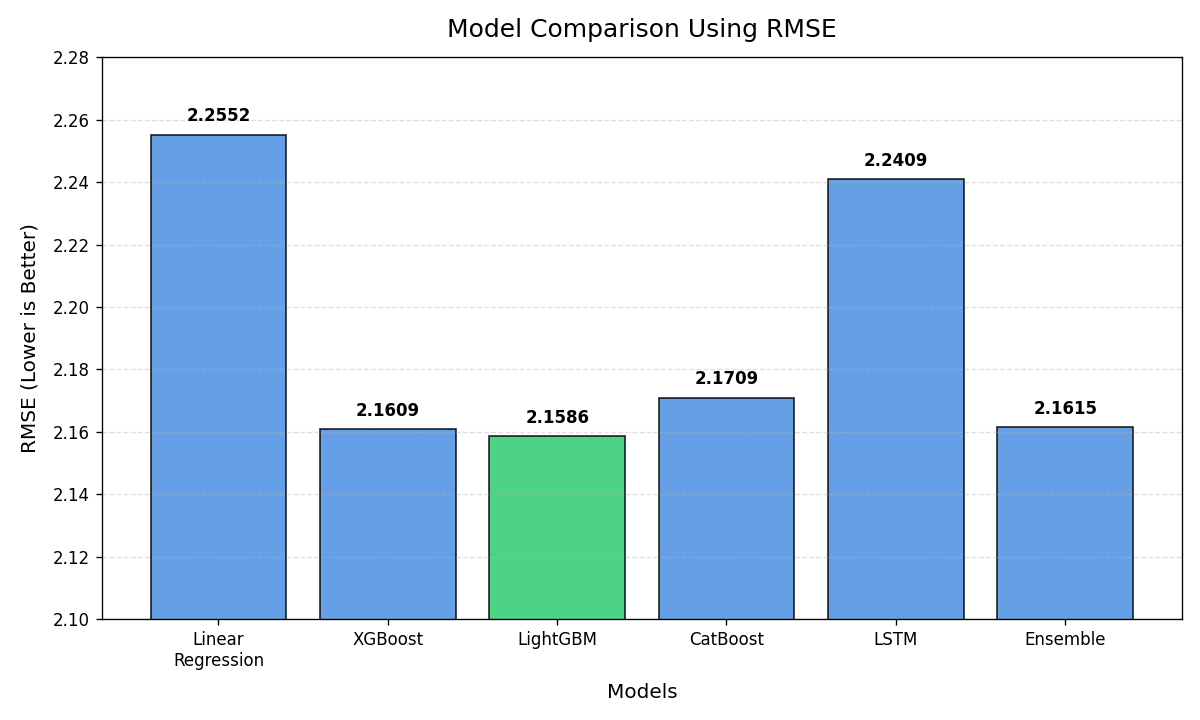

In [57]:
import matplotlib.pyplot as plt

# Model names
models = [
    'Linear\nRegression',
    'XGBoost',
    'LightGBM',
    'CatBoost',
    'LSTM',
    'Ensemble'
]

# RMSE values
rmse = [
    2.2552380220070805,
    2.160860964177554,
    2.1585967461730027,
    2.1708978264998136,
    2.240939440935853,
    2.161507112984715
]

# Create figure
plt.figure(figsize=(10,6))

bars = plt.bar(models, rmse)

# Highlight the best model
best_index = rmse.index(min(rmse))
bars[best_index].set_color('green')

# Add values above bars
for i, value in enumerate(rmse):
    plt.text(i, value + 0.003, f"{value:.4f}", ha='center', fontsize=10)

plt.title("Model Comparison Using RMSE", fontsize=16)
plt.xlabel("Models", fontsize=12)
plt.ylabel("RMSE (Lower is Better)", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

In [58]:
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "XGBoost",
        "LightGBM",
        "CatBoost",
        "LSTM",
        "Ensemble"
    ],
    "RMSE": [
        2.2552380220070805,
        2.160860964177554,
        2.1585967461730027,
        2.1708978264998136,
        2.240939440935853,
        2.161507112984715
    ],
    "MAE": [
        1.1609739419624492,
        1.133061170578003,
        1.1330937915335058,
        1.139278543245514,
        1.2330591678619385,
        1.156532215846953
    ]
})

results = results.sort_values("RMSE")

print(results)

               Model      RMSE       MAE
2           LightGBM  2.158597  1.133094
1            XGBoost  2.160861  1.133061
5           Ensemble  2.161507  1.156532
3           CatBoost  2.170898  1.139279
4               LSTM  2.240939  1.233059
0  Linear Regression  2.255238  1.160974


streamlit
